# Lab 6: Association Rule Mining with Apriori and FP-Growth

**Name:** Anushka Nanaware
**Course:** MSCS-634-M50 - Advanced Big Data and Data Mining
**Lab Assignment:** Lab 6 - Association Rule Mining Using Apriori and FP-Growth on the Online Retail Dataset

## Step 1: Data Preparation

In [2]:
!pip install -q mlxtend ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)       # 352 = Online Retail dataset
df_raw = online_retail.data.original        # the full table
print("Shape:", df_raw.shape)
print(df_raw.isnull().sum())
df_raw.head()

Shape: (541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df = df_raw.copy()
before = len(df)

# 1) Remove rows with no item name
df = df.dropna(subset=["Description"])

# 2) Make item names tidy (remove extra spaces, same capitalization)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["Description"] = df["Description"].str.strip().str.upper()

# 3) Remove cancelled invoices (their numbers start with "C")
df = df[~df["InvoiceNo"].str.startswith("C")]

# 4) Remove rows with zero or negative quantity or price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# 5) Remove non-product rows like postage and bank charges
non_products = ["POST", "DOT", "M", "BANK CHARGES", "CRUK", "PADS", "D", "C2", "S", "AMAZONFEE"]
df = df[~df["StockCode"].astype(str).str.upper().isin(non_products)]

# 6) Keep one country so baskets are consistent (UK is about 90% of the data)
df = df[df["Country"] == "United Kingdom"]

# 7) Remove repeated lines of the same item in the same invoice
df = df.drop_duplicates(subset=["InvoiceNo", "Description"])

print("Rows before cleaning:", before)
print("Rows after cleaning :", len(df))
print("Number of invoices (baskets):", df["InvoiceNo"].nunique())
print("Number of different items   :", df["Description"].nunique())

Rows before cleaning: 541909
Rows after cleaning : 473484
Number of invoices (baskets): 17902
Number of different items   : 3988


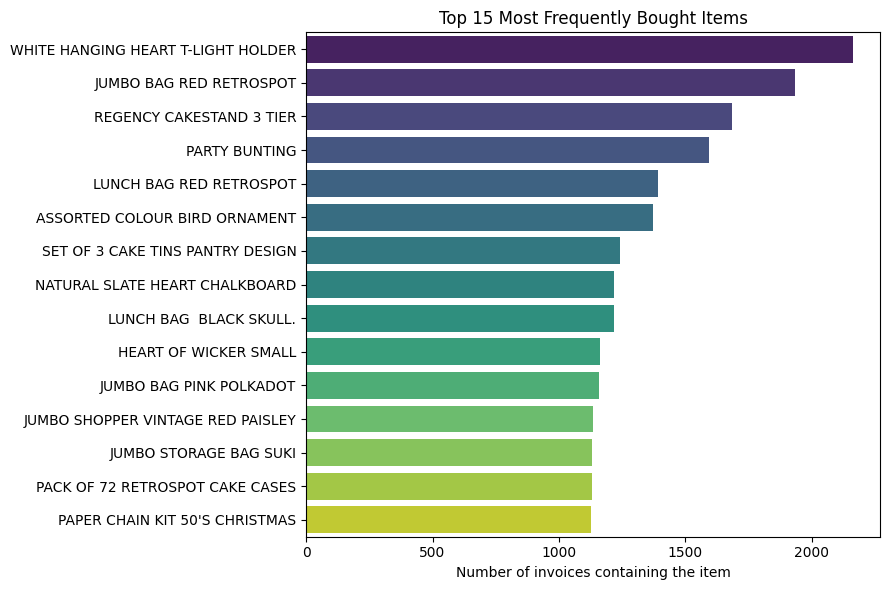

In [5]:
top_items = df["Description"].value_counts().head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_items.values, y=top_items.index, hue=top_items.index,
            palette="viridis", legend=False)
plt.title("Top 15 Most Frequently Bought Items")
plt.xlabel("Number of invoices containing the item")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [6]:
# Keep only the 100 most popular items. This keeps the table small and the mining fast.
TOP_N_ITEMS = 100
keep = df["Description"].value_counts().head(TOP_N_ITEMS).index
df_top = df[df["Description"].isin(keep)]

# Rows = invoices, columns = items, values = True/False
basket = pd.crosstab(df_top["InvoiceNo"], df_top["Description"]).gt(0)

# A basket with only 1 item can't show a pattern, so remove it
basket = basket[basket.sum(axis=1) >= 2]

print("Basket table shape (invoices x items):", basket.shape)
print("Average items per basket:", round(basket.sum(axis=1).mean(), 2))
basket.head()

Basket table shape (invoices x items): (11614, 100)
Average items per basket: 7.3


Description,6 RIBBONS RUSTIC CHARM,60 TEATIME FAIRY CAKE CASES,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE PINK,ALARM CLOCK BAKELIKE RED,ANTIQUE SILVER T-LIGHT GLASS,ASSORTED COLOUR BIRD ORNAMENT,BAKING SET 9 PIECE RETROSPOT,BATHROOM METAL SIGN,CHARLOTTE BAG PINK POLKADOT,...,SPOTTY BUNTING,STRAWBERRY CERAMIC TRINKET BOX,STRAWBERRY CHARLOTTE BAG,VICTORIAN GLASS HANGING T-LIGHT,VINTAGE SNAP CARDS,WHITE HANGING HEART T-LIGHT HOLDER,WOOD BLACK BOARD ANT WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,WOODLAND CHARLOTTE BAG
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536367,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536373,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,True,True,False
536375,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,True,True,False
536376,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536378,False,True,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


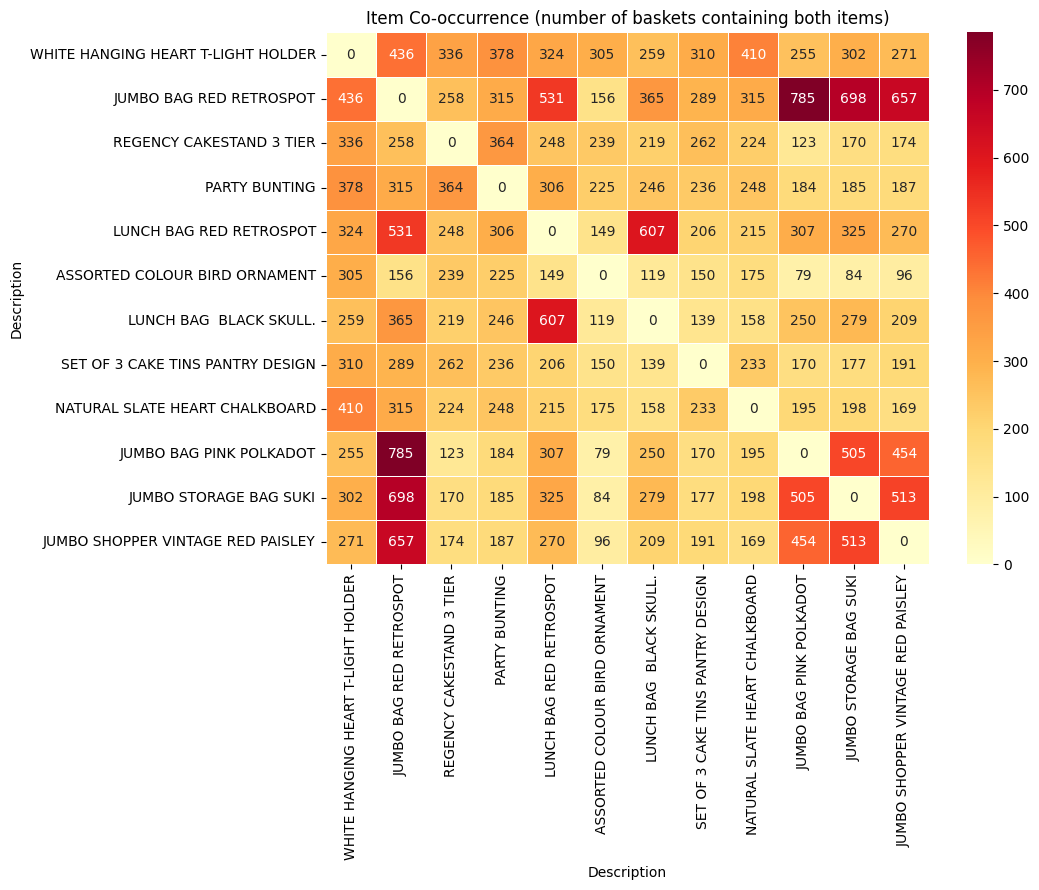

In [7]:
# Use the 12 most common items so the heatmap is readable
top12 = basket.sum().sort_values(ascending=False).head(12).index
b = basket[top12].astype(int)

# How many baskets contain both item A and item B
co_array = b.T.to_numpy() @ b.to_numpy()
np.fill_diagonal(co_array, 0)            # an item with itself is not interesting
co = pd.DataFrame(co_array, index=top12, columns=top12)

plt.figure(figsize=(11, 9))
sns.heatmap(co, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5)
plt.title("Item Co-occurrence (number of baskets containing both items)")
plt.tight_layout()
plt.show()

### Step 1 Observations: Data Preparation

- I used the **Online Retail dataset** from the UCI repository. It has 541,909 rows and 8 columns (invoice number, stock code, item description, quantity, date, unit price, customer ID, and country). Each row is one item on one invoice, and one invoice is treated as one shopping basket.
- **Cleaning steps:** I removed rows with no item description (1,454 rows), cancelled invoices (invoice numbers starting with "C"), rows with zero or negative quantity or price, and non-product rows such as postage and bank charges. I also tidied the item names, kept United Kingdom invoices only, and removed repeated lines of the same item in the same invoice.
- Cleaning reduced the data from **541,909** rows to **473,484** rows, covering **17,902** invoices (baskets) and **3,988** different items.
- **Most frequent items:** The most commonly bought items are the white hanging heart t-light holder (about 2,150 invoices), the jumbo bag red retrospot (about 1,930), and the regency cakestand 3 tier (about 1,680). Many of the top items are home decor and bag products.
- For mining, I kept the **100 most popular items** and removed baskets with fewer than 2 of them. The final basket table has **11,614 baskets** and **100 items**, with an average of **7.3 items per basket**.
- **Heatmap:** The darkest square shows that the jumbo bag red retrospot and the jumbo bag pink polkadot appear together in 785 baskets. Other strong pairs are the jumbo bag red retrospot with the jumbo storage bag suki (698 baskets) and with the jumbo shopper vintage red paisley (657 baskets), and the lunch bag red retrospot with the lunch bag black skull (607 baskets). Customers often buy several items from the same product family, which makes these pairs good candidates for strong rules later.

## Step 2: Frequent Itemset Mining Using Apriori

In [8]:
import time
from mlxtend.frequent_patterns import apriori

# Minimum support: an itemset must appear in at least 2% of baskets
min_support = 0.02

# Run 3 times and average, so the time is more reliable (we compare it with FP-Growth later)
run_times = []
for _ in range(3):
    start = time.perf_counter()
    freq_apriori = apriori(basket, min_support=min_support, use_colnames=True)
    run_times.append(time.perf_counter() - start)
apriori_time = np.mean(run_times)

# Add the number of items in each itemset
freq_apriori["length"] = freq_apriori["itemsets"].apply(len)

print("Min support:", min_support, "| baskets:", len(basket))
print("Frequent itemsets found:", len(freq_apriori))
print()
print("How many itemsets of each size:")
print(freq_apriori["length"].value_counts().sort_index().to_string())
print()
print("Apriori time (average of 3 runs):", round(apriori_time, 3), "seconds")

Min support: 0.02 | baskets: 11614
Frequent itemsets found: 498

How many itemsets of each size:
length
1    100
2    312
3     81
4      5

Apriori time (average of 3 runs): 1.694 seconds


In [9]:
freq_sorted = freq_apriori.sort_values("support", ascending=False).reset_index(drop=True)
freq_sorted.head(15)

,support,itemsets,length
0,0.176683,(WHITE HANGING HEART T-LIGHT HOLDER),1
1,0.163768,(JUMBO BAG RED RETROSPOT),1
2,0.134579,(REGENCY CAKESTAND 3 TIER),1
3,0.128207,(PARTY BUNTING),1
4,0.118994,(LUNCH BAG RED RETROSPOT),1
5,0.109523,(ASSORTED COLOUR BIRD ORNAMENT),1
6,0.103668,(LUNCH BAG BLACK SKULL.),1
7,0.103237,(SET OF 3 CAKE TINS PANTRY DESIGN),1
8,0.100052,(NATURAL SLATE HEART CHALKBOARD),1
9,0.098760,(JUMBO BAG PINK POLKADOT),1


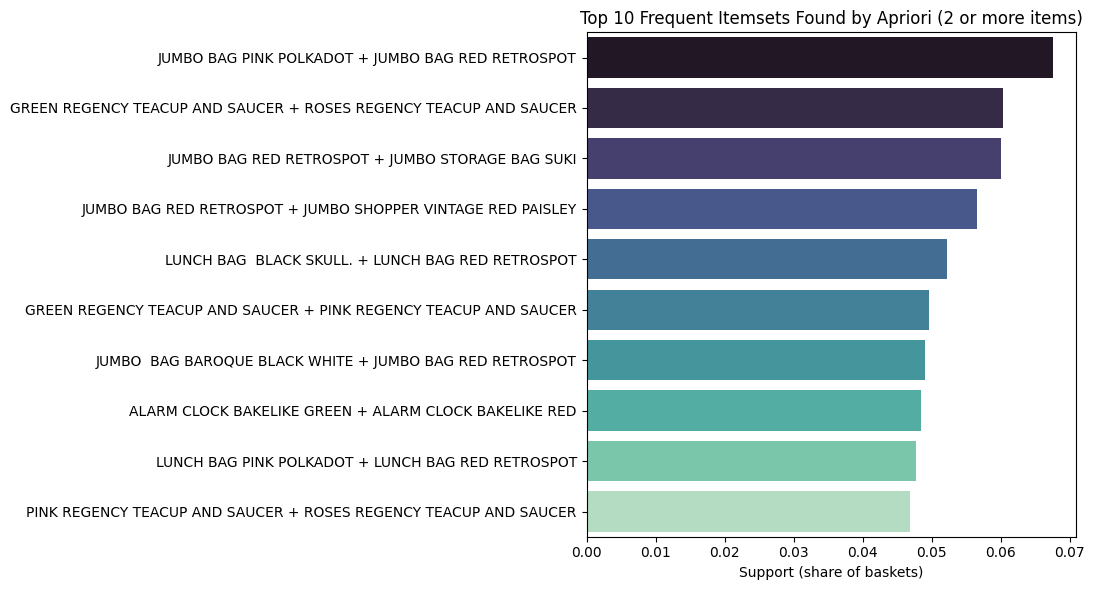

In [10]:
top_sets = freq_apriori[freq_apriori["length"] >= 2].sort_values("support", ascending=False).head(10).copy()
top_sets["itemset_name"] = top_sets["itemsets"].apply(lambda s: " + ".join(sorted(s)))

plt.figure(figsize=(11, 6))
sns.barplot(data=top_sets, x="support", y="itemset_name",
            hue="itemset_name", palette="mako", legend=False)
plt.title("Top 10 Frequent Itemsets Found by Apriori (2 or more items)")
plt.xlabel("Support (share of baskets)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [11]:
import time
from mlxtend.frequent_patterns import apriori

min_support = 0.02      # try 0.03 if it is still slow
max_len = 3             # only look for itemsets of up to 3 items

run_times = []
for _ in range(3):
    start = time.perf_counter()
    freq_apriori = apriori(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    run_times.append(time.perf_counter() - start)
apriori_time = np.mean(run_times)

freq_apriori["length"] = freq_apriori["itemsets"].apply(len)

print("Min support:", min_support, "| max itemset size:", max_len, "| baskets:", len(basket))
print("Frequent itemsets found:", len(freq_apriori))
print()
print(freq_apriori["length"].value_counts().sort_index().to_string())
print()
print("Apriori time (average of 3 runs):", round(apriori_time, 3), "seconds")

Min support: 0.02 | max itemset size: 3 | baskets: 11614
Frequent itemsets found: 493

length
1    100
2    312
3     81

Apriori time (average of 3 runs): 0.802 seconds


### Step 2 Observations: Apriori

- I used a minimum support of **0.02**, so an itemset must appear in at least 2% of the 11,614 baskets (about 232 baskets).
- My first run had no limit on itemset size. It found **498** frequent itemsets (100 with 1 item, 312 with 2 items, 81 with 3 items, and 5 with 4 items) in about 1.7 seconds.
- To keep the later FP-Growth run safe and fair, I limited itemsets to a **maximum of 3 items** for both algorithms. This gave **493** frequent itemsets (100 single items, 312 pairs, and 81 triples). Apriori took about **0.80 seconds** on average over 3 runs.
- The most frequent single item is the white hanging heart t-light holder, which appears in about 17.7% of baskets.
- The most frequent pair is the **jumbo bag pink polkadot + jumbo bag red retrospot** (about 6.8% of baskets). The next ones are the green + roses regency teacup and saucer (about 6.0%) and the jumbo bag red retrospot + jumbo storage bag suki (about 6.0%).
- Most of the top pairs are different designs of the same kind of product, such as jumbo bags, lunch bags, and regency teacups. This is common in retail data.

## Step 3: Frequent Itemset Mining Using FP-Growth

In [12]:
from mlxtend.frequent_patterns import fpgrowth

# Same min_support and max_len as Apriori
run_times = []
for _ in range(3):
    start = time.perf_counter()
    freq_fp = fpgrowth(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    run_times.append(time.perf_counter() - start)
fpgrowth_time = np.mean(run_times)

freq_fp["length"] = freq_fp["itemsets"].apply(len)

print("Min support:", min_support, "| max itemset size:", max_len)
print("Frequent itemsets found by FP-Growth:", len(freq_fp))
print()
print(freq_fp["length"].value_counts().sort_index().to_string())
print()
print("FP-Growth time (average of 3 runs):", round(fpgrowth_time, 3), "seconds")

Min support: 0.02 | max itemset size: 3
Frequent itemsets found by FP-Growth: 493

length
1    100
2    312
3     81

FP-Growth time (average of 3 runs): 31.961 seconds


In [13]:
freq_fp_sorted = freq_fp.sort_values("support", ascending=False).reset_index(drop=True)
freq_fp_sorted.head(15)

,support,itemsets,length
0,0.176683,(WHITE HANGING HEART T-LIGHT HOLDER),1
1,0.163768,(JUMBO BAG RED RETROSPOT),1
2,0.134579,(REGENCY CAKESTAND 3 TIER),1
3,0.128207,(PARTY BUNTING),1
4,0.118994,(LUNCH BAG RED RETROSPOT),1
5,0.109523,(ASSORTED COLOUR BIRD ORNAMENT),1
6,0.103668,(LUNCH BAG BLACK SKULL.),1
7,0.103237,(SET OF 3 CAKE TINS PANTRY DESIGN),1
8,0.100052,(NATURAL SLATE HEART CHALKBOARD),1
9,0.098760,(JUMBO BAG PINK POLKADOT),1


In [14]:
# 1) Did both algorithms find exactly the same itemsets with the same support?
apriori_set = {(frozenset(i), round(s, 10)) for i, s in zip(freq_apriori["itemsets"], freq_apriori["support"])}
fp_set = {(frozenset(i), round(s, 10)) for i, s in zip(freq_fp["itemsets"], freq_fp["support"])}
print("Same itemsets and support values?", apriori_set == fp_set)

# 2) Speed comparison
speed = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Time (seconds)": [apriori_time, fpgrowth_time],
    "Itemsets found": [len(freq_apriori), len(freq_fp)],
})
print()
print(speed.round(4).to_string(index=False))

faster = "FP-Growth" if fpgrowth_time < apriori_time else "Apriori"
ratio = max(apriori_time, fpgrowth_time) / min(apriori_time, fpgrowth_time)
print()
print(f"{faster} was faster, by about {ratio:.1f}x")

Same itemsets and support values? True

Algorithm  Time (seconds)  Itemsets found
  Apriori          0.8023             493
FP-Growth         31.9608             493

Apriori was faster, by about 39.8x


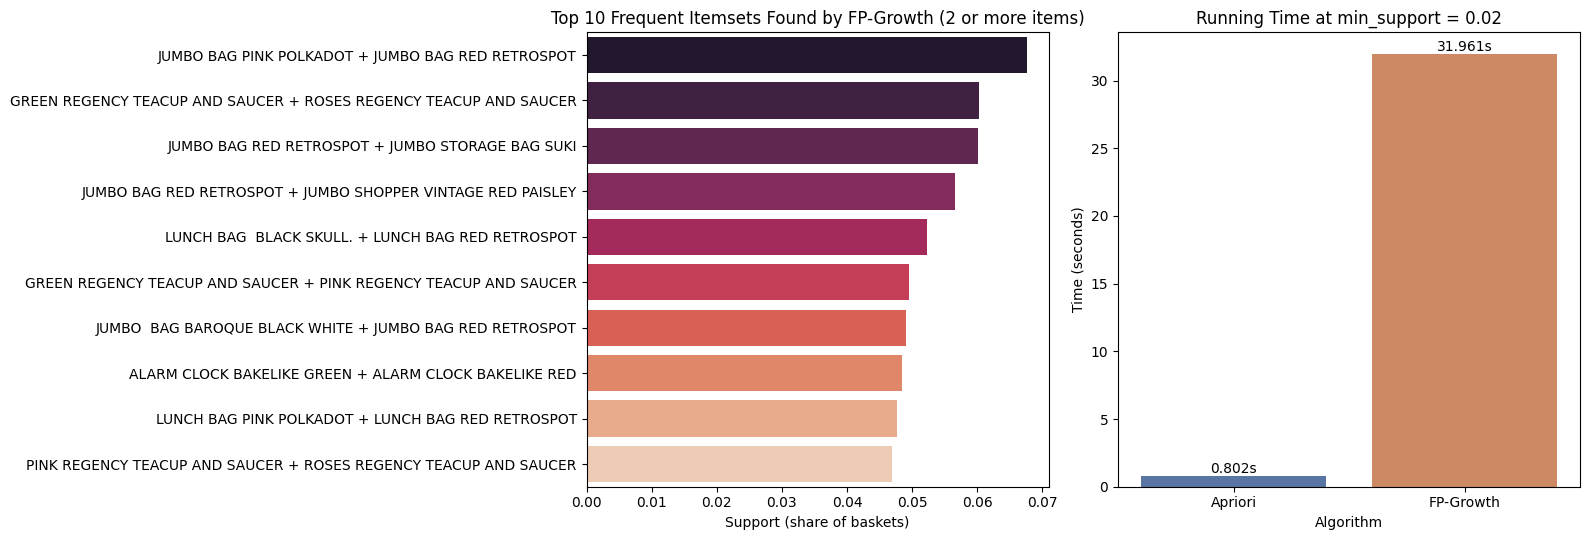

In [15]:
top_fp = freq_fp[freq_fp["length"] >= 2].sort_values("support", ascending=False).head(10).copy()
top_fp["itemset_name"] = top_fp["itemsets"].apply(lambda s: " + ".join(sorted(s)))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(data=top_fp, x="support", y="itemset_name", hue="itemset_name",
            palette="rocket", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Frequent Itemsets Found by FP-Growth (2 or more items)")
axes[0].set_xlabel("Support (share of baskets)")
axes[0].set_ylabel("")

sns.barplot(data=speed, x="Algorithm", y="Time (seconds)", hue="Algorithm",
            palette=["#4c72b0", "#dd8452"], legend=False, ax=axes[1])
for i, v in enumerate(speed["Time (seconds)"]):
    axes[1].text(i, v, f"{v:.3f}s", ha="center", va="bottom")
axes[1].set_title(f"Running Time at min_support = {min_support}")

plt.tight_layout()
plt.show()

### Step 3 Observations: FP-Growth

- I used the same minimum support (**0.02**) and the same maximum itemset size (3) as Apriori, so the comparison is fair.
- FP-Growth found **493** frequent itemsets, exactly the same number as Apriori. The check in the code confirmed that the itemsets and their support values are identical. The top itemsets in the table and chart are the same as in Apriori.
- **Speed:** Apriori took about **0.80 seconds** and FP-Growth took about **31.96 seconds**, so **Apriori was faster, by about 40 times**.
- This is the opposite of what is often expected. FP-Growth is usually the faster algorithm, because it builds a compact tree of the baskets and avoids generating candidate itemsets. In this lab the data is small (100 items, itemsets of at most 3 items), so Apriori's search is already very small. Also, in the Python library I used (mlxtend), Apriori works on the whole table of True/False values at once, while FP-Growth builds its tree basket by basket, which is slower for this kind of data.
- Both algorithms give exactly the same result. They only differ in how they get there and how long it takes.

## Step 4: Generating and Analyzing Association Rules

In [16]:
from mlxtend.frequent_patterns import association_rules

min_confidence = 0.5     # a rule must be right at least 50% of the time

def make_rules(freq_itemsets):
    try:
        rules = association_rules(freq_itemsets, metric="confidence", min_threshold=min_confidence)
    except TypeError:
        # some mlxtend versions need the number of baskets
        rules = association_rules(freq_itemsets, num_itemsets=len(basket),
                                  metric="confidence", min_threshold=min_confidence)
    rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]].copy()
    rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    rules["consequents"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
    return rules

rules_apriori = make_rules(freq_apriori)
rules_fp = make_rules(freq_fp)

print("Minimum confidence:", min_confidence)
print("Rules from Apriori itemsets  :", len(rules_apriori))
print("Rules from FP-Growth itemsets:", len(rules_fp))

# Are the two sets of rules exactly the same?
key = lambda df: set(zip(df["antecedents"], df["consequents"],
                         df["support"].round(8), df["confidence"].round(8), df["lift"].round(8)))
print("Same rules from both algorithms?", key(rules_apriori) == key(rules_fp))

Minimum confidence: 0.5
Rules from Apriori itemsets  : 272
Rules from FP-Growth itemsets: 272
Same rules from both algorithms? True


In [17]:
# Keep only rules with a real positive link (lift above 1), strongest first
rules = rules_apriori[rules_apriori["lift"] > 1].sort_values("lift", ascending=False).reset_index(drop=True)

print("Rules with lift > 1:", len(rules))
print()
print(rules[["support", "confidence", "lift"]].describe().round(3))

rules.head(10).round(3)

Rules with lift > 1: 272

       support  confidence     lift
count  272.000     272.000  272.000
mean     0.028       0.627    6.975
std      0.009       0.092    2.334
min      0.020       0.501    3.080
25%      0.022       0.547    5.468
50%      0.026       0.610    6.222
75%      0.032       0.685    8.792
max      0.068       0.903   12.547


,antecedents,consequents,support,confidence,lift
0,"CHARLOTTE BAG SUKI DESIGN, STRAWBERRY CHARLOTT...",WOODLAND CHARLOTTE BAG,0.025,0.730,12.547
1,"CHARLOTTE BAG PINK POLKADOT, CHARLOTTE BAG SUK...",WOODLAND CHARLOTTE BAG,0.024,0.716,12.304
2,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",STRAWBERRY CHARLOTTE BAG,0.026,0.709,12.277
3,"CHARLOTTE BAG PINK POLKADOT, WOODLAND CHARLOTT...",STRAWBERRY CHARLOTTE BAG,0.022,0.700,12.121
4,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",CHARLOTTE BAG PINK POLKADOT,0.026,0.698,12.058
5,"CHARLOTTE BAG SUKI DESIGN, WOODLAND CHARLOTTE BAG",STRAWBERRY CHARLOTTE BAG,0.025,0.695,12.028
6,"RED RETROSPOT CHARLOTTE BAG, STRAWBERRY CHARLO...",CHARLOTTE BAG PINK POLKADOT,0.027,0.688,11.887
7,"CHARLOTTE BAG PINK POLKADOT, STRAWBERRY CHARLO...",WOODLAND CHARLOTTE BAG,0.022,0.691,11.865
8,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.042,0.703,11.779
9,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.042,0.710,11.779


In [18]:
for _, r in rules.head(5).iterrows():
    print(f"If a basket has [{r['antecedents']}], it also has [{r['consequents']}] "
          f"{r['confidence']*100:.0f}% of the time (lift {r['lift']:.2f}, "
          f"in {r['support']*100:.1f}% of all baskets).")

If a basket has [CHARLOTTE BAG SUKI DESIGN, STRAWBERRY CHARLOTTE BAG], it also has [WOODLAND CHARLOTTE BAG] 73% of the time (lift 12.55, in 2.5% of all baskets).
If a basket has [CHARLOTTE BAG PINK POLKADOT, CHARLOTTE BAG SUKI DESIGN], it also has [WOODLAND CHARLOTTE BAG] 72% of the time (lift 12.30, in 2.4% of all baskets).
If a basket has [RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTTE BAG], it also has [STRAWBERRY CHARLOTTE BAG] 71% of the time (lift 12.28, in 2.6% of all baskets).
If a basket has [CHARLOTTE BAG PINK POLKADOT, WOODLAND CHARLOTTE BAG], it also has [STRAWBERRY CHARLOTTE BAG] 70% of the time (lift 12.12, in 2.2% of all baskets).
If a basket has [RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTTE BAG], it also has [CHARLOTTE BAG PINK POLKADOT] 70% of the time (lift 12.06, in 2.6% of all baskets).


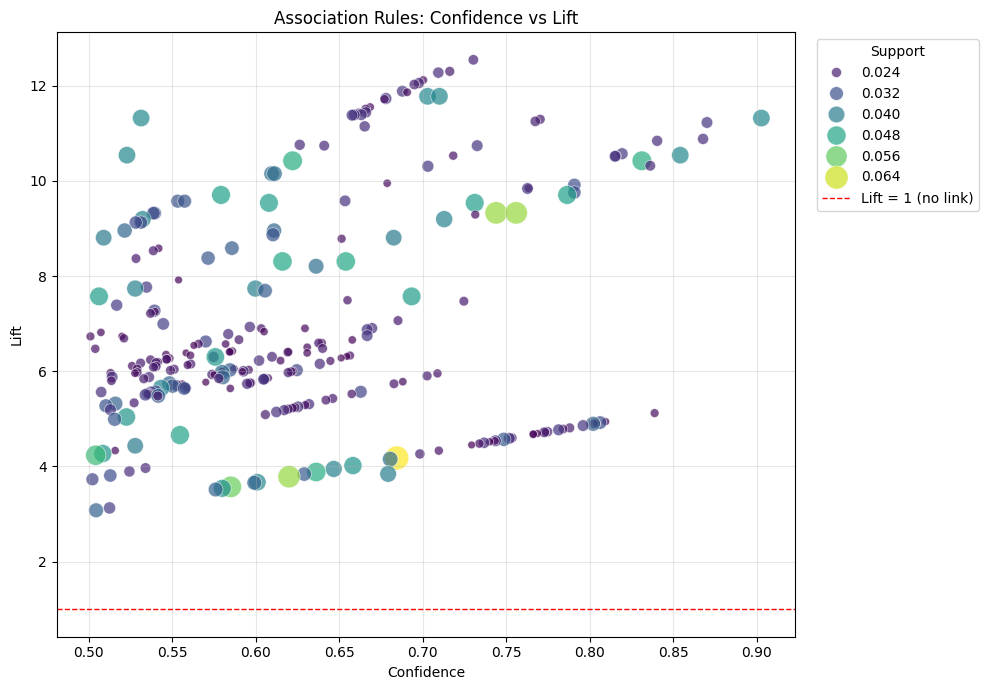

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=rules, x="confidence", y="lift", size="support", hue="support",
                palette="viridis", sizes=(30, 300), alpha=0.7, ax=ax)

ax.axhline(1, color="red", linestyle="--", linewidth=1, label="Lift = 1 (no link)")
ax.set_title("Association Rules: Confidence vs Lift")
ax.set_xlabel("Confidence")
ax.set_ylabel("Lift")
ax.legend(title="Support", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Step 4 Observations: Association Rules

- I generated rules from the frequent itemsets of both algorithms using a minimum confidence of **0.5**. Both gave **272 rules**, and the rules were identical.
- **Support** shows how often a rule applies, **confidence** shows how reliable it is, and **lift** shows how much stronger the link is than random chance. A lift above 1 means the items are bought together more than expected.
- All 272 rules have a lift above 1. Lift ranges from 3.08 to 12.55 (median 6.22), confidence ranges from 0.50 to 0.90 (average 0.63), and support ranges from 0.020 to 0.068. This tells us the patterns are real, not random.
- **Strongest rule:** If a basket has the **charlotte bag suki design** and the **strawberry charlotte bag**, it also has the **woodland charlotte bag** 73% of the time (lift 12.55, in 2.5% of all baskets). That is about 12.5 times more likely than for a random basket.
- **Other meaningful patterns:**
  - Red retrospot charlotte bag + woodland charlotte bag leads to the strawberry charlotte bag (confidence 71%, lift 12.28).
  - Green regency teacup and saucer + roses regency teacup and saucer leads to the pink regency teacup and saucer (confidence 70%, lift 11.78).
- The strongest rules link products from the same family (charlotte bags, regency teacups). Customers who buy part of a set often want the rest of the set.
- **Business use:** The store could display these products together, sell them as bundles, or suggest the missing item when a customer adds two items from a set to their cart.
- **Scatter plot:** All the dots are well above the red line at lift = 1. Most rules have a lift between 4 and 12. The rules in the top-right of the plot have both high confidence and high lift, so they are the most useful ones to act on. Bigger dots show rules that apply to more baskets.

## Step 5: Comparative Analysis

In [20]:
summary = pd.DataFrame({
    "Measure": ["Frequent itemsets found", "Association rules generated", "Running time (seconds)"],
    "Apriori": [str(len(freq_apriori)), str(len(rules_apriori)), f"{apriori_time:.3f}"],
    "FP-Growth": [str(len(freq_fp)), str(len(rules_fp)), f"{fpgrowth_time:.3f}"],
})
print(f"Settings used for both: min_support = {min_support}, max itemset size = {max_len}, min_confidence = {min_confidence}")
summary

Settings used for both: min_support = 0.02, max itemset size = 3, min_confidence = 0.5


,Measure,Apriori,FP-Growth
0,Frequent itemsets found,493,493
1,Association rules generated,272,272
2,Running time (seconds),0.802,31.961


In [21]:
support_levels = [0.05, 0.04, 0.03, 0.02]   # from strict to relaxed; the last value should be your own min_support
scale_rows = []

for sup in support_levels:
    t0 = time.perf_counter()
    a = apriori(basket, min_support=sup, use_colnames=True, max_len=max_len)
    t_a = time.perf_counter() - t0

    t0 = time.perf_counter()
    f = fpgrowth(basket, min_support=sup, use_colnames=True, max_len=max_len)
    t_f = time.perf_counter() - t0

    scale_rows.append({"min_support": sup, "Itemsets": len(a),
                       "Apriori (s)": t_a, "FP-Growth (s)": t_f})

scale_df = pd.DataFrame(scale_rows)
print(scale_df.round(4).to_string(index=False))

 min_support  Itemsets  Apriori (s)  FP-Growth (s)
        0.05       104       0.8340         8.7108
        0.04       133       0.9257         6.2510
        0.03       201       0.4264         9.1683
        0.02       493       1.0915        31.3849


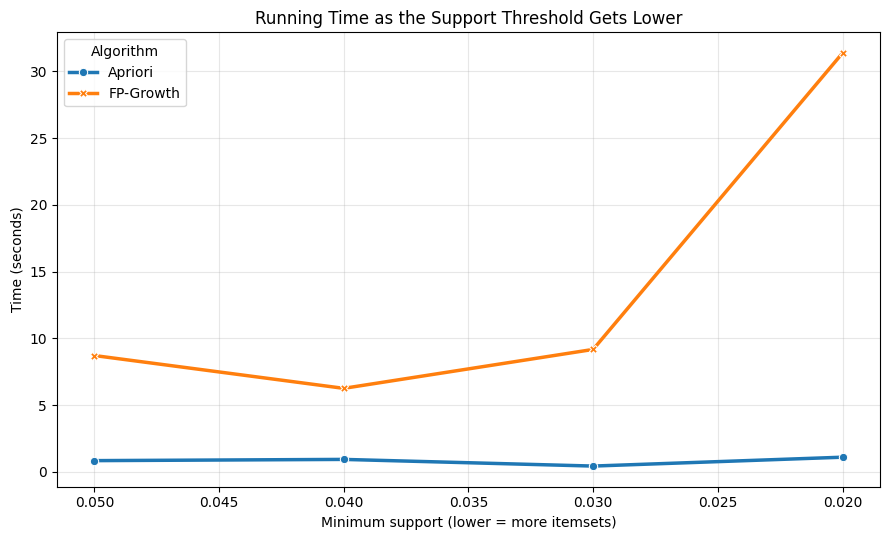

In [22]:
plot_df = scale_df.melt(id_vars="min_support", value_vars=["Apriori (s)", "FP-Growth (s)"],
                        var_name="Algorithm", value_name="Time (seconds)")
plot_df["Algorithm"] = plot_df["Algorithm"].str.replace(" (s)", "", regex=False)

plt.figure(figsize=(9, 5.5))
sns.lineplot(data=plot_df, x="min_support", y="Time (seconds)", hue="Algorithm",
             style="Algorithm", markers=True, dashes=False, linewidth=2.5)
plt.gca().invert_xaxis()      # lower support (more itemsets) on the right
plt.title("Running Time as the Support Threshold Gets Lower")
plt.xlabel("Minimum support (lower = more itemsets)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Step 5: Comparative Analysis

**Comparing the results**

| Measure | Apriori | FP-Growth |
|---|---|---|
| Frequent itemsets found | 493 | 493 |
| Association rules generated | 272 | 272 |
| Running time (seconds) | 0.802 | 31.961 |

Both algorithms found exactly the same frequent itemsets and the same association rules, with identical support, confidence and lift values. This is expected, because both are exact methods and only differ in how they search. The settings were the same for both (min_support = 0.02, max itemset size = 3, min_confidence = 0.5).

**Which was faster, and why?**

Apriori was faster, taking about 0.80 seconds compared with about 31.96 seconds for FP-Growth, which is about 40 times faster. The timing experiment shows this was not a one-time result. At every support level I tested (0.05, 0.04, 0.03 and 0.02), Apriori took about 0.4 to 1.1 seconds, while FP-Growth took 6 to 31 seconds. At the lowest support (0.02), FP-Growth got much slower while Apriori stayed about the same.

I think this is because my basket table is small: only the 100 most popular items, and itemsets limited to 3 items. With data this small, Apriori's repeated scans are cheap. In the library I used (mlxtend), Apriori counts itemsets on the whole table at once, while FP-Growth builds its tree basket by basket and then searches it again and again, and this costs more time here. In theory, FP-Growth has the advantage when there are many items, long itemsets, or very low support, because it avoids generating and testing a huge number of candidates. My result only describes this dataset, this library, and these settings, and does not mean Apriori is faster in general.

**Challenges and how I solved them**
- **Large dataset:** The Online Retail data has over 500,000 rows. I cleaned it by removing missing descriptions, cancelled invoices, zero or negative quantities and prices, and non-product rows like postage. I kept United Kingdom invoices only, so the baskets were consistent.
- **Too many items:** Using all 3,988 products would make the basket table too big for Colab. I kept the 100 most frequent items and removed baskets with fewer than 2 of them.
- **Session crash:** My first FP-Growth run kept running and then crashed the Colab session. I fixed it by limiting itemsets to a maximum of 3 items (max_len = 3) for both algorithms, and used a minimum support of 0.02.
- **Lost variables after restart:** After the crash, my variables were gone and I got a NameError. I fixed it by re-running the cells from the top in order.
- **Choosing thresholds:** I tested a few values for support and confidence and picked ones that gave a useful number of itemsets and rules, not too few and not too many.